# TP : Détection de faux billets avec l'apprentissage automatique (Projet 7)

**Durée estimée :** 2 heures · **Niveau :** débutant, bases de Python et de statistique · **Domaine :** banque et finance

## Objectifs

À la fin de ce TP, vous saurez :

1. identifier le **type d'apprentissage** d'un problème et formuler sa question financière ;
2. charger un jeu de données public depuis la source UCI et l'explorer graphiquement ;
3. préparer les données (doublons, mise à l'échelle) sans fuite de données ;
4. entraîner et comparer plusieurs modèles de classification à partir d'une référence simple ;
5. évaluer un modèle avec une matrice de confusion, les courbes ROC et précision-rappel, et une courbe d'apprentissage ;
6. interpréter un modèle, en discuter les limites et en tirer des conclusions.

## 1. Question posée et type d'apprentissage

**Question.** À partir de quatre statistiques calculées sur l'image numérisée d'un billet, peut-on **prédire si le billet est authentique ou faux** ?

**Intérêt financier.** Un faux billet accepté par un guichet automatique, un commerçant ou une banque est une perte sèche. À l'inverse, rejeter un vrai billet fait perdre du temps et dégrade l'expérience client. Les deux erreurs n'ont donc **pas le même coût** : laisser passer un faux billet est en général plus coûteux que de contrôler un billet authentique de trop. Cette asymétrie guidera le choix des métriques.

Ce problème relève de l'**apprentissage supervisé**, plus précisément de la **classification binaire** :

- **Supervisé** : chaque billet est associé à une étiquette connue (authentique ou faux). Le modèle apprend à partir de paires (entrée, sortie) déjà annotées.
- **Classification** : la cible prend un nombre fini de valeurs, et non une valeur réelle. Si on cherchait à prédire une valeur monétaire, ce serait une **régression**.
- **Binaire** : il n'y a que deux classes. Avec plus de deux classes, on parlerait de classification multiclasse.

Pour le distinguer de l'apprentissage non supervisé, on se demande : **la bonne réponse est-elle connue pour chaque exemple ?** Ici, oui : l'authenticité est renseignée pour tous les billets. Un algorithme de partitionnement ne recevrait pas cette étiquette et chercherait seulement des groupes.

> **Remarque.** Dans ce TP, la classe « faux billet » est la **classe positive** : c'est elle que l'on cherche à détecter. Le **rappel** mesure donc la part des faux billets réellement détectés.

## 2. Le jeu de données

Le jeu de données **Banknote Authentication** provient du dépôt UCI Machine Learning Repository (jeu n° 267). Les données ont été extraites d'images de billets authentiques et falsifiés, numérisées, puis résumées par une **transformée en ondelettes**. Chaque ligne est un billet décrit par quatre statistiques de son image.

| Variable | Type | Description |
|---|---|---|
| `variance` | numérique | Variance de l'image transformée en ondelettes |
| `skewness` | numérique | Asymétrie (skewness) de l'image transformée |
| `kurtosis` | numérique | Aplatissement (kurtosis) de l'image transformée |
| `entropy` | numérique | Entropie de l'image |
| `classe` | binaire (cible) | 0 = billet authentique, 1 = faux billet |

> Le fichier d'origine n'a pas d'en-tête : nous nommons les colonnes nous-mêmes. Dans la documentation UCI, la variable `kurtosis` est écrite « curtosis ». La convention usuelle est 0 = authentique et 1 = faux ; vérifiez-la dans la documentation UCI.

Le chargement se fait directement depuis la source UCI (page : <https://archive.ics.uci.edu/dataset/267/banknote+authentication>), sans téléchargement manuel.

In [35]:
import io
import os
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, learning_curve, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_auc_score, average_precision_score, make_scorer,
                             precision_score, RocCurveDisplay, PrecisionRecallDisplay)

np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

In [36]:
URL_ZIP = "https://archive.ics.uci.edu/static/public/267/banknote+authentication.zip"
COLONNES = ["variance", "skewness", "kurtosis", "entropy", "classe"]

def charger_donnees():
    """Télécharge le jeu depuis UCI. Deux plans de secours : le paquet ucimlrepo, puis un fichier local."""

    try:
        requete = urllib.request.Request(URL_ZIP, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(requete, timeout=30) as reponse:
            archive = zipfile.ZipFile(io.BytesIO(reponse.read()))
        nom = [n for n in archive.namelist() if n.endswith(".txt")][0]
        with archive.open(nom) as f:
            return pd.read_csv(f, header=None, names=COLONNES), "UCI (archive zip)"
    except Exception as erreur:
        print("Zip UCI indisponible :", type(erreur).__name__)

    try:
        from ucimlrepo import fetch_ucirepo
        jeu = fetch_ucirepo(id=267)
        data = pd.concat([jeu.data.features, jeu.data.targets], axis=1)
        data.columns = COLONNES
        return data, "UCI (paquet ucimlrepo)"
    except Exception as erreur:
        print("ucimlrepo indisponible :", type(erreur).__name__, "(dans Colab : !pip install ucimlrepo)")

    if os.path.exists("data_banknote_authentication.txt"):
        return pd.read_csv("data_banknote_authentication.txt", header=None, names=COLONNES), "fichier local"
    raise RuntimeError("Impossible de charger les données : vérifiez la connexion ou ajoutez le fichier .txt.")

df, source = charger_donnees()
print("Source utilisée :", source)
print("Dimensions :", df.shape)
df.head()

Source utilisée : UCI (archive zip)
Dimensions : (1372, 5)


,variance,skewness,kurtosis,entropy,classe
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


## 3. Première exploration

Avant toute modélisation, on examine la structure des données : types des colonnes, valeurs manquantes, **doublons** et statistiques descriptives. Ces étapes servent à repérer les problèmes de qualité qui affecteront le modèle.

In [37]:

df.info()
print("\nValeurs manquantes par colonne :")
print(df.isna().sum())
print("\nLignes dupliquées :", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   kurtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   classe    1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Valeurs manquantes par colonne :
variance    0
skewness    0
kurtosis    0
entropy     0
classe      0
dtype: int64

Lignes dupliquées : 24


In [38]:
df.describe().round(2)

,variance,skewness,kurtosis,entropy,classe
count,1372.00,1372.00,1372.00,1372.00,1372.00
mean,0.43,1.92,1.40,-1.19,0.44
std,2.84,5.87,4.31,2.10,0.50
min,-7.04,-13.77,-5.29,-8.55,0.00
25%,-1.77,-1.71,-1.57,-2.41,0.00
50%,0.50,2.32,0.62,-0.59,0.00
75%,2.82,6.81,3.18,0.39,1.00
max,6.82,12.95,17.93,2.45,1.00


**Lecture.** Le jeu contient 1 372 billets décrits par 4 variables numériques, sans aucune valeur manquante. En revanche, **24 lignes sont des doublons exacts** : nous les retirerons avant le découpage. Les échelles diffèrent d'une variable à l'autre (l'asymétrie va d'environ −14 à 13, l'entropie de −8,5 à 2,5, l'aplatissement de −5 à 18). La moyenne de `classe` vaut 0,44 : environ 44 % des billets sont faux. Cette mise à l'échelle sera utile à la régression logistique et au SVM, qui sont sensibles aux unités.

## 4. Visualisation des données

### 4.1 Répartition des classes

Il faut vérifier si les deux classes sont équilibrées. Un déséquilibre fort rendrait l'exactitude trompeuse.

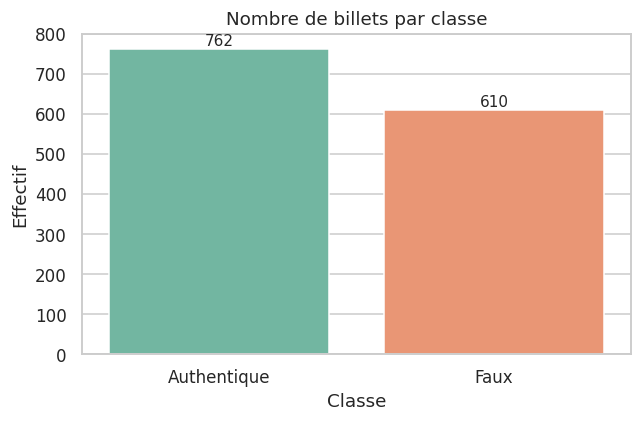

In [39]:
df["Classe"] = df["classe"].map({0: "Authentique", 1: "Faux"})
variables_num = ["variance", "skewness", "kurtosis", "entropy"]
titres = ["Variance", "Asymétrie (skewness)", "Aplatissement (kurtosis)", "Entropie"]

fig, ax = plt.subplots(figsize=(6, 4))
ordre = df["Classe"].value_counts().index
sns.countplot(data=df, x="Classe", order=ordre, hue="Classe", legend=False, ax=ax)
for patch in ax.patches:
    ax.annotate(f"{int(patch.get_height())}",
                (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Nombre de billets par classe")
ax.set_xlabel("Classe")
ax.set_ylabel("Effectif")
plt.tight_layout()
plt.show()

**Lecture.** Les classes sont modérément déséquilibrées : 762 billets authentiques (55,5 %) contre 610 faux (44,5 %). Aucune classe n'est négligeable, mais l'exactitude seule reste insuffisante. Nous utiliserons donc une **validation stratifiée**, qui conserve ces proportions dans chaque pli, et nous suivrons aussi le rappel de la classe « faux ».

### 4.2 Distributions des variables selon la classe

Un histogramme par classe montre si une variable aide à distinguer les billets : plus les distributions sont séparées, plus la variable est informative.

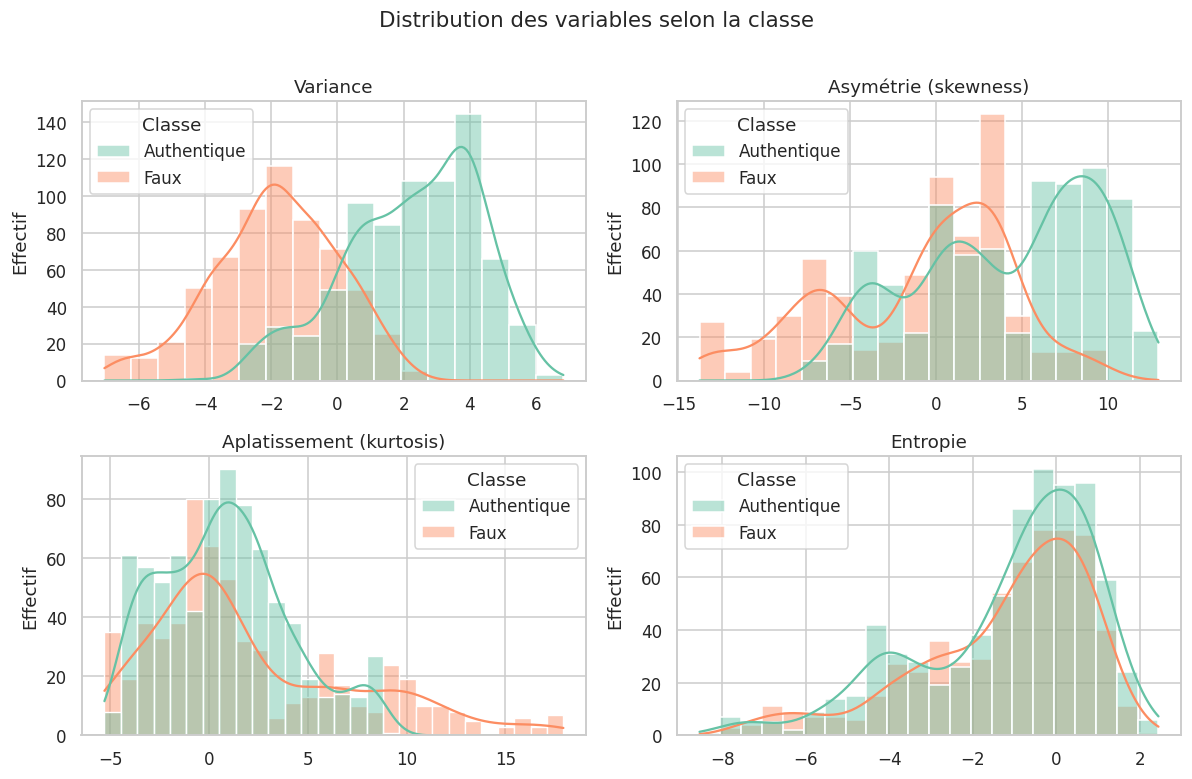

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, var, titre in zip(axes.ravel(), variables_num, titres):
    sns.histplot(data=df, x=var, hue="Classe", hue_order=["Authentique", "Faux"],
                 kde=True, alpha=0.45, ax=ax)
    ax.set_title(titre)
    ax.set_xlabel("")
    ax.set_ylabel("Effectif")
plt.suptitle("Distribution des variables selon la classe", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

**Lecture.** La **variance** est la variable la plus discriminante : les faux billets sont centrés autour de −2, les billets authentiques autour de +3 ou +4, avec un recouvrement limité. L'**asymétrie** sépare aussi en partie les deux classes. L'**aplatissement** et surtout l'**entropie** se recouvrent presque complètement : seules, elles distinguent mal les billets. Un modèle apprendra automatiquement ces différences, mais il est bon de les vérifier.

### 4.3 Relation entre deux variables

Un nuage de points colorié par classe permet de visualiser une **frontière de séparation** possible dans un plan à deux dimensions.

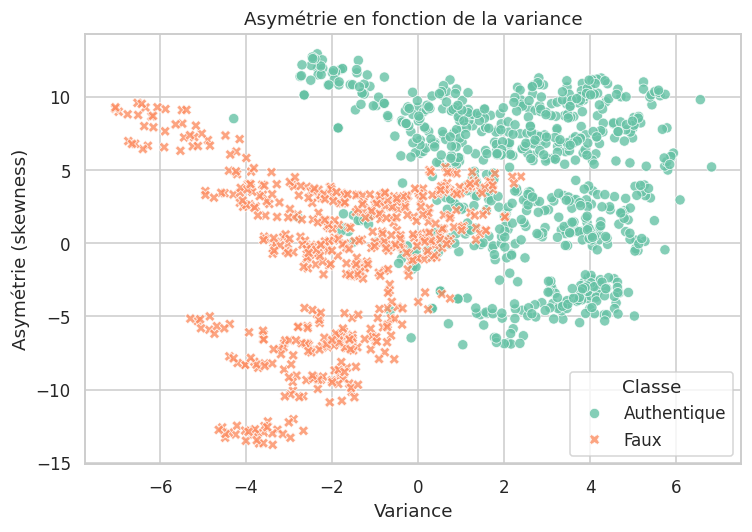

In [41]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x="variance", y="skewness", hue="Classe", style="Classe",
                hue_order=["Authentique", "Faux"], s=45, alpha=0.8, ax=ax)
ax.set_title("Asymétrie en fonction de la variance")
ax.set_xlabel("Variance")
ax.set_ylabel("Asymétrie (skewness)")
ax.legend(title="Classe")
plt.tight_layout()
plt.show()

**Lecture.** Dans le plan variance–asymétrie, les faux billets se regroupent surtout à gauche (variance négative) et les billets authentiques à droite. Les deux nuages se chevauchent dans une zone centrale, et la frontière qui les sépare semble **courbe** plutôt que droite. Cela justifie d'essayer un modèle non linéaire (SVM à noyau RBF, arbres) en plus de la régression logistique.

### 4.4 Boîtes à moustaches et corrélations

Les boîtes à moustaches résument la médiane, les quartiles et les valeurs extrêmes. La matrice de corrélation indique les liens linéaires entre variables : deux variables très corrélées apportent une information redondante.

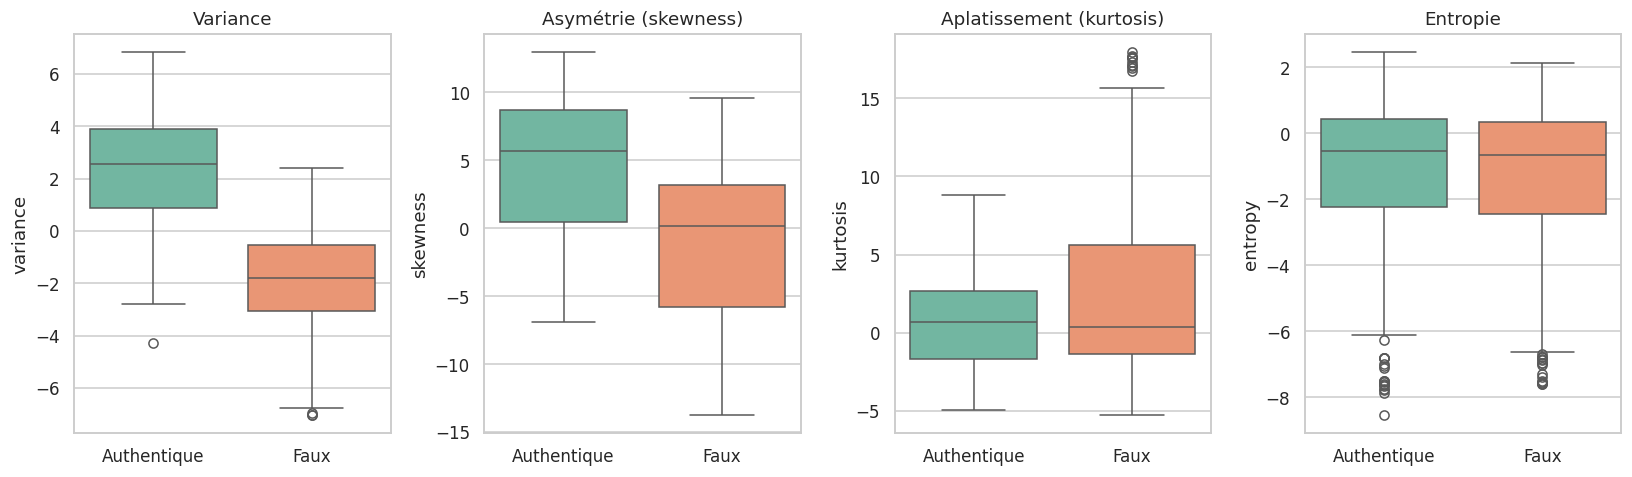

In [42]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.5))
for ax, var, titre in zip(axes, variables_num, titres):
    sns.boxplot(data=df, x="Classe", y=var, hue="Classe", order=["Authentique", "Faux"],
                hue_order=["Authentique", "Faux"], legend=False, ax=ax)
    ax.set_title(titre)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

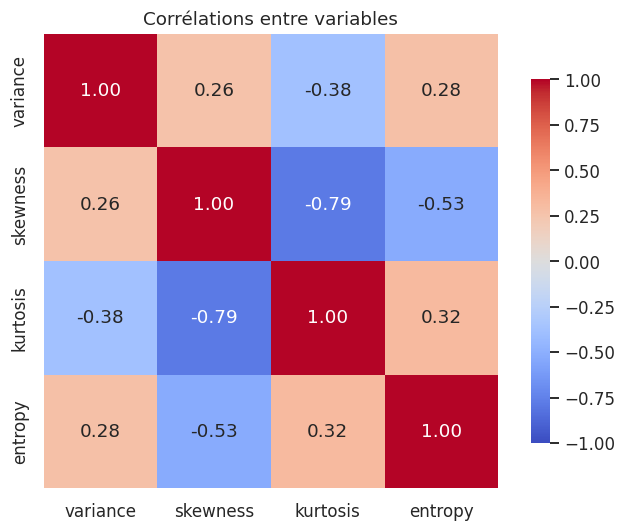

In [43]:
fig, ax = plt.subplots(figsize=(6.5, 5))
corr = df[variables_num].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Corrélations entre variables")
plt.tight_layout()
plt.show()

**Lecture.** Les boîtes à moustaches confirment les histogrammes : les médianes de la variance et de l'asymétrie diffèrent nettement entre les classes, celles de l'entropie presque pas. La corrélation la plus forte est entre l'asymétrie et l'aplatissement (−0,79) : elles portent en partie la même information. Ce n'est pas gênant pour un arbre ou une forêt, et la régression logistique de scikit-learn est régularisée par défaut, ce qui limite l'effet de cette redondance.

## 5. Préparation des données

Règles à respecter :

- **Ne jamais utiliser le jeu de test pendant la préparation.** Toute transformation (moyenne, écart-type) est apprise sur l'entraînement uniquement.
- **Supprimer les doublons avant le découpage.** Un même billet présent en double peut se retrouver à la fois dans l'entraînement et dans le test : le modèle serait alors évalué sur des exemples qu'il a déjà vus, ce qui gonfle le score. C'est une **fuite de données**.
- **Traiter les valeurs manquantes.** Il n'y en a pas ici, aucune imputation n'est nécessaire.
- **Standardiser les variables numériques** : $z = \dfrac{x - \bar x}{s}$, moyenne nulle et écart-type 1. Toutes les variables sont numériques, il n'y a donc pas d'encodage à faire.

Ces étapes sont regroupées dans un `Pipeline` : la même chaîne est alors appliquée à l'entraînement, à la validation et au test.

In [44]:
df_propre = df.drop_duplicates(subset=variables_num + ["classe"]).reset_index(drop=True)
print("Observations avant :", len(df), "| après suppression des doublons :", len(df_propre))

X = df_propre[variables_num]
y = df_propre["classe"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Entraînement :", X_train.shape[0], "| Test :", X_test.shape[0])
print("Proportions de faux billets dans l'entraînement :", round(y_train.mean(), 3))
print("Proportions de faux billets dans le test        :", round(y_test.mean(), 3))

# 4) Prétraitement : standardisation (appris sur l'entraînement uniquement, via le Pipeline)
preprocesseur = StandardScaler()

Observations avant : 1372 | après suppression des doublons : 1348
Entraînement : 1011 | Test : 337
Proportions de faux billets dans l'entraînement : 0.453
Proportions de faux billets dans le test        : 0.451


## 6. Entraînement et comparaison de modèles

### 6.1 Principe de la comparaison

Nous comparons plusieurs algorithmes, du plus simple au plus complexe. La **référence** (*baseline*) est un classifieur qui ignore les données et prédit toujours la classe majoritaire. Tout modèle utile doit faire mieux que cette référence.

Pour comparer équitablement, on utilise une **validation croisée stratifiée à 5 plis sur l'ensemble d'entraînement**. Le jeu de test reste de côté jusqu'à l'évaluation finale.

Comme les deux erreurs n'ont pas le même coût, on ne se contente pas de l'exactitude. On suit aussi :

- le **rappel** de la classe « faux » : part des faux billets détectés ;
- la **précision** de la classe « faux » : part des billets signalés qui sont bien faux ;
- le **ROC-AUC** et le **PR-AUC** (aire sous la courbe précision-rappel), qui évaluent le modèle sur tous les seuils de décision.

In [45]:
modeles = {
    "Référence (classe majoritaire)": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": LogisticRegression(max_iter=1000),
    "SVM (noyau RBF)": SVC(kernel="rbf"),
    "Arbre de décision": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=200, random_state=42),
}

pipelines = {nom: Pipeline([("prep", preprocesseur), ("modele", m)])
             for nom, m in modeles.items()}

scoring = {
    "exactitude": "accuracy",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "rappel": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
}

validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultats = []
for nom, pipe in pipelines.items():
    cv = cross_validate(pipe, X_train, y_train, cv=validation, scoring=scoring)
    resultats.append({
        "Modèle": nom,
        "Exactitude": cv["test_exactitude"].mean(),
        "Écart-type exactitude": cv["test_exactitude"].std(),
        "Rappel (faux)": cv["test_rappel"].mean(),
        "Précision (faux)": cv["test_precision"].mean(),
        "ROC-AUC": cv["test_roc_auc"].mean(),
        "PR-AUC": cv["test_pr_auc"].mean(),
    })

tableau = (pd.DataFrame(resultats)
           .sort_values(["PR-AUC", "Exactitude"], ascending=False)
           .reset_index(drop=True))
tableau.round(3)

,Modèle,Exactitude,Écart-type exactitude,Rappel (faux),Précision (faux),ROC-AUC,PR-AUC
0,SVM (noyau RBF),0.998,0.002,1.000,0.996,1.000,1.000
1,Régression logistique,0.994,0.002,0.998,0.989,1.000,1.000
2,Forêt aléatoire,0.991,0.011,0.998,0.983,1.000,1.000
3,Arbre de décision,0.967,0.007,0.980,0.950,0.981,0.963
4,Référence (classe majoritaire),0.547,0.002,0.000,0.000,0.500,0.453


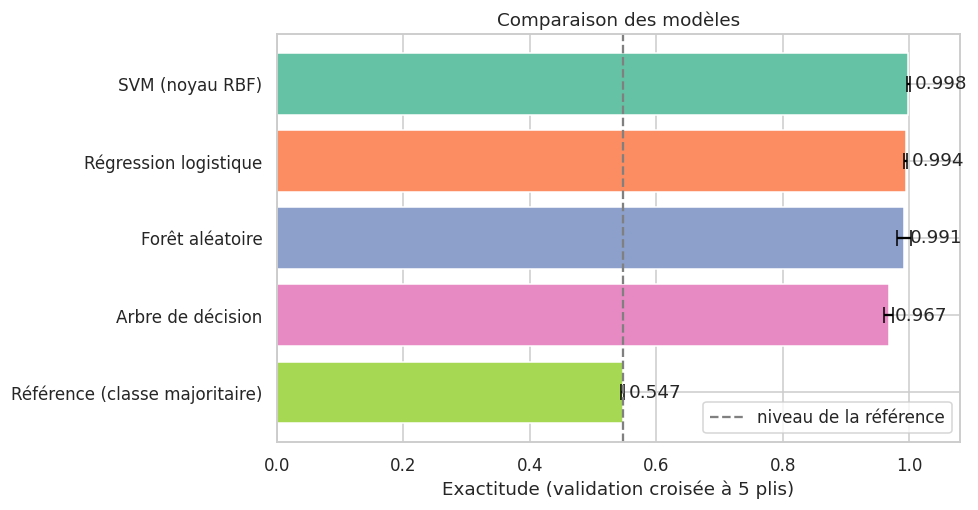

In [46]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(tableau["Modèle"], tableau["Exactitude"],
        xerr=tableau["Écart-type exactitude"], capsize=5,
        color=sns.color_palette("Set2", len(tableau)))
ax.set_xlim(0, 1.08)
ax.invert_yaxis()
ref = tableau.loc[tableau["Modèle"].str.startswith("Référence"), "Exactitude"].values[0]
ax.axvline(ref, color="grey", linestyle="--", label="niveau de la référence")
for i, val in enumerate(tableau["Exactitude"]):
    ax.text(val + 0.01, i, f"{val:.3f}", va="center")
ax.set_xlabel("Exactitude (validation croisée à 5 plis)")
ax.set_title("Comparaison des modèles")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Lecture.** La référence atteint une exactitude de 0,547 (elle prédit toujours « authentique ») et un **rappel de 0** : elle ne détecte aucun faux billet. C'est la preuve que l'exactitude seule est trompeuse. Les trois meilleurs modèles dépassent 0,99 d'exactitude : SVM (0,998), régression logistique (0,994) et forêt aléatoire (0,991, la plus variable d'un pli à l'autre, écart-type 0,011). Leurs ROC-AUC et PR-AUC sont arrondis à 1,000. L'arbre de profondeur 4 est un cran en dessous (0,967). Les écarts entre les trois premiers sont de l'ordre de quelques billets sur 1 011 : le classement est **fragile** et ne prouve pas qu'un modèle est meilleur que l'autre.

## 7. Évaluation finale sur le jeu de test

Le modèle choisi est entraîné sur tout l'ensemble d'entraînement, puis évalué **une seule fois** sur le jeu de test. Ce score est une estimation de la performance sur de nouveaux billets.

Nous sélectionnons automatiquement le modèle ayant le meilleur PR-AUC en validation croisée (l'exactitude départage les égalités).

In [47]:
def score_faux(pipe, X_):
    if hasattr(pipe, "predict_proba"):
        return pipe.predict_proba(X_)[:, 1]
    return pipe.decision_function(X_)

meilleur_nom = tableau.iloc[0]["Modèle"]
meilleur_pipe = pipelines[meilleur_nom]
meilleur_pipe.fit(X_train, y_train)
y_pred = meilleur_pipe.predict(X_test)
y_score = score_faux(meilleur_pipe, X_test)

print("Meilleur modèle :", meilleur_nom)
print(f"Exactitude sur le jeu de test : {accuracy_score(y_test, y_pred):.3f}")
print(f"ROC-AUC sur le jeu de test    : {roc_auc_score(y_test, y_score):.3f}")
print(f"PR-AUC sur le jeu de test     : {average_precision_score(y_test, y_score):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["Authentique", "Faux"]))

Meilleur modèle : SVM (noyau RBF)
Exactitude sur le jeu de test : 0.997
ROC-AUC sur le jeu de test    : 1.000
PR-AUC sur le jeu de test     : 1.000

              precision    recall  f1-score   support

 Authentique       1.00      0.99      1.00       185
        Faux       0.99      1.00      1.00       152

    accuracy                           1.00       337
   macro avg       1.00      1.00      1.00       337
weighted avg       1.00      1.00      1.00       337



### 7.1 Matrice de confusion

La matrice de confusion croise la classe réelle et la classe prédite. La diagonale contient les réussites ; les autres cases montrent **quelles erreurs** sont commises. Ici, les deux types d'erreur ont un sens métier précis :

- **faux négatif** : un faux billet accepté comme authentique (l'erreur la plus coûteuse) ;
- **faux positif** : un billet authentique rejeté à tort (une gêne, mais sans perte financière directe).

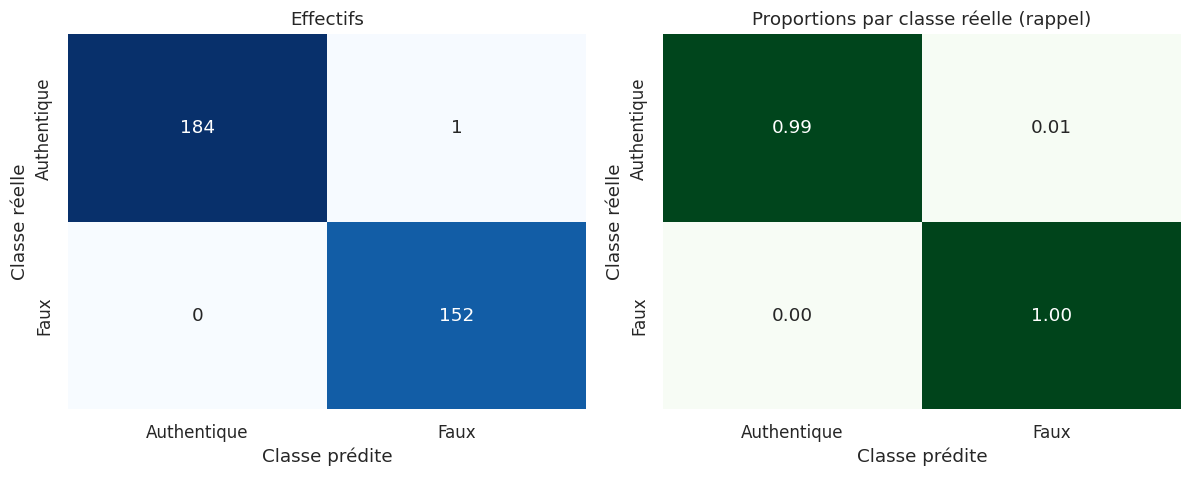

In [48]:
# Matrice de confusion : valeurs absolues et proportions par ligne
classes = ["Authentique", "Faux"]
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes,
            yticklabels=classes, cbar=False, ax=axes[0])
axes[0].set_title("Effectifs")
axes[0].set_xlabel("Classe prédite")
axes[0].set_ylabel("Classe réelle")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", xticklabels=classes,
            yticklabels=classes, vmin=0, vmax=1, cbar=False, ax=axes[1])
axes[1].set_title("Proportions par classe réelle (rappel)")
axes[1].set_xlabel("Classe prédite")
axes[1].set_ylabel("Classe réelle")
plt.tight_layout()
plt.show()

**Lecture.** Sur les 337 billets du test, le modèle commet **une seule erreur** : un billet authentique rejeté à tort (faux positif). Aucun faux billet n'est accepté (0 faux négatif) : le rappel de la classe « faux » vaut 1,00, ce qui est le résultat souhaité vu l'asymétrie des coûts. Une erreur isolée ne suffit pas à conclure : c'est pourquoi la validation croisée sert à juger la stabilité.

### 7.2 Courbes ROC et précision-rappel

La courbe **ROC** compare le taux de faux billets détectés au taux de vrais billets rejetés à tort, pour tous les seuils. La courbe **précision-rappel** montre le compromis entre détecter tous les faux billets et ne signaler que de vrais faux. Une aire proche de 1 indique un modèle qui sépare presque parfaitement les deux classes, quel que soit le seuil.

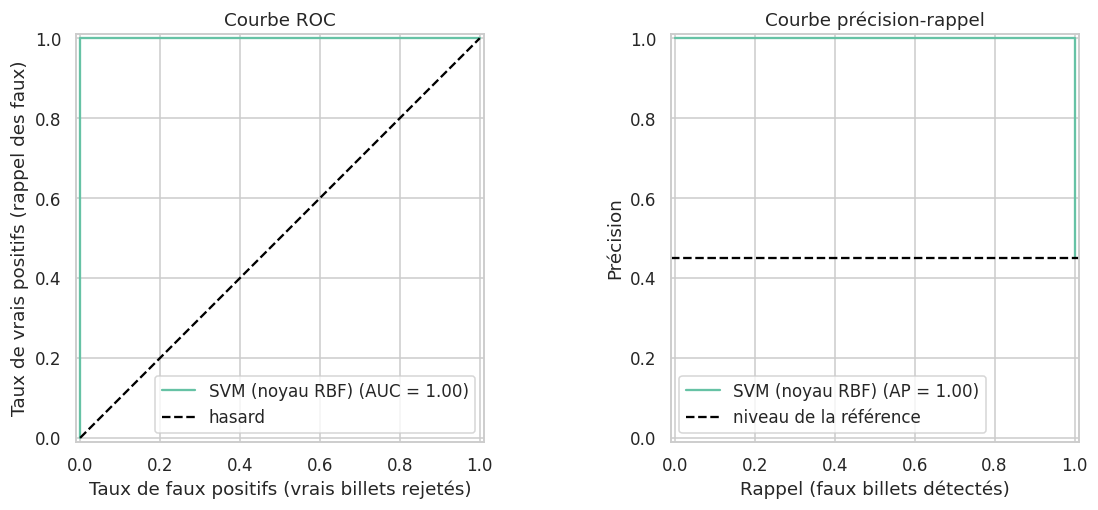

In [49]:
# Courbes ROC et précision-rappel sur le jeu de test
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
RocCurveDisplay.from_predictions(y_test, y_score, ax=axes[0], name=meilleur_nom)
axes[0].plot([0, 1], [0, 1], "k--", label="hasard")
axes[0].set_title("Courbe ROC")
axes[0].set_xlabel("Taux de faux positifs (vrais billets rejetés)")
axes[0].set_ylabel("Taux de vrais positifs (rappel des faux)")
axes[0].legend(loc="lower right")

PrecisionRecallDisplay.from_predictions(y_test, y_score, ax=axes[1], name=meilleur_nom)
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="niveau de la référence")
axes[1].set_title("Courbe précision-rappel")
axes[1].set_xlabel("Rappel (faux billets détectés)")
axes[1].set_ylabel("Précision")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

**Lecture.** Sur le test, le ROC-AUC et le PR-AUC sont arrondis à 1,000 : presque tous les faux billets reçoivent un score plus élevé que les billets authentiques. Les courbes longent le coin supérieur gauche (ROC) et le bord supérieur (précision-rappel), très au-dessus du niveau de la référence. L'unique erreur de la matrice de confusion tient au seuil de décision par défaut : un seuil légèrement différent suffirait à l'éviter sur ce jeu de test. Un score aussi élevé reflète un problème facile avec ces quatre variables ; il ne garantit pas la même performance sur de nouveaux scanners.

### 7.3 Courbe d'apprentissage

La courbe d'apprentissage répond à une question pratique : **le modèle manque-t-il de données, ou de flexibilité ?**

- Si les courbes d'entraînement et de validation convergent vers un score faible : **sous-apprentissage** (biais élevé).
- Si l'écart reste grand : **surapprentissage** (variance élevée) ; plus de données ou une régularisation aideraient.

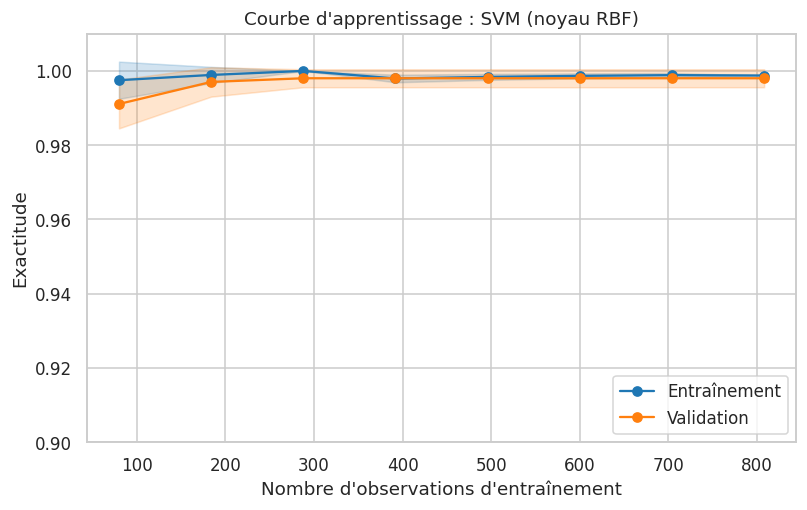

In [50]:
# Courbe d'apprentissage du meilleur modèle
tailles, scores_train, scores_val = learning_curve(
    meilleur_pipe, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 8), cv=validation, scoring="accuracy", n_jobs=-1
)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for scores, label, couleur in [(scores_train, "Entraînement", "tab:blue"),
                               (scores_val, "Validation", "tab:orange")]:
    moyenne, ecart = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(tailles, moyenne, "o-", color=couleur, label=label)
    ax.fill_between(tailles, moyenne - ecart, moyenne + ecart, alpha=0.2, color=couleur)
ax.set_xlabel("Nombre d'observations d'entraînement")
ax.set_ylabel("Exactitude")
ax.set_title(f"Courbe d'apprentissage : {meilleur_nom}")
ax.set_ylim(0.9, 1.01)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Lecture.** Dès 80 observations environ, les scores d'entraînement et de validation sont déjà proches de 0,99, et les deux courbes se confondent ensuite. Il n'y a ni sous-apprentissage (le score est élevé) ni surapprentissage notable (l'écart est quasi nul). Ajouter des données n'améliorerait presque pas ce modèle : il est suffisant pour ce jeu.

## 8. Interprétation du modèle

### 8.1 Importance des variables

La forêt aléatoire fournit une mesure d'importance : la réduction moyenne de l'impureté de Gini apportée par chaque variable. Elle indique quelles statistiques pèsent le plus dans la décision. Nous l'entraînons ici sur le même prétraitement pour interpréter le modèle.

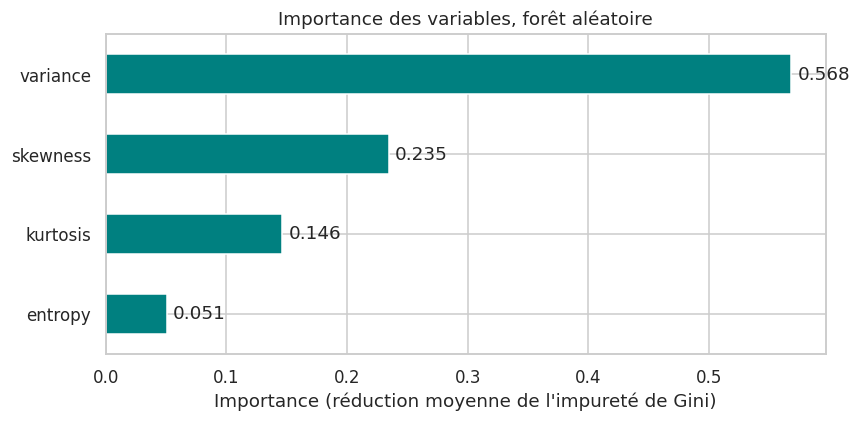

In [51]:
# Importance des variables pour la forêt aléatoire
foret = Pipeline([("prep", preprocesseur),
                  ("modele", RandomForestClassifier(n_estimators=200, random_state=42))])
foret.fit(X_train, y_train)

importances = pd.Series(foret.named_steps["modele"].feature_importances_, index=variables_num)
importances = importances.sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
importances.plot.barh(ax=ax, color="teal")
for i, val in enumerate(importances):
    ax.text(val + 0.005, i, f"{val:.3f}", va="center")
ax.set_xlabel("Importance (réduction moyenne de l'impureté de Gini)")
ax.set_title("Importance des variables, forêt aléatoire")
plt.tight_layout()
plt.show()

**Lecture.** La **variance** domine nettement (plus de la moitié de l'importance), suivie de l'asymétrie puis de l'aplatissement. L'entropie pèse très peu, ce qui est cohérent avec les histogrammes. Attention toutefois : cette importance dépend du modèle et peut être biaisée quand des variables sont corrélées, comme l'asymétrie et l'aplatissement. Elle sert à orienter l'analyse, pas à établir une causalité.

### 8.2 Frontières de décision

Pour visualiser comment un modèle sépare les classes, on se limite à **deux variables** et on colore chaque point du plan selon la prédiction. C'est une vue pédagogique : le modèle complet utilise les quatre variables.

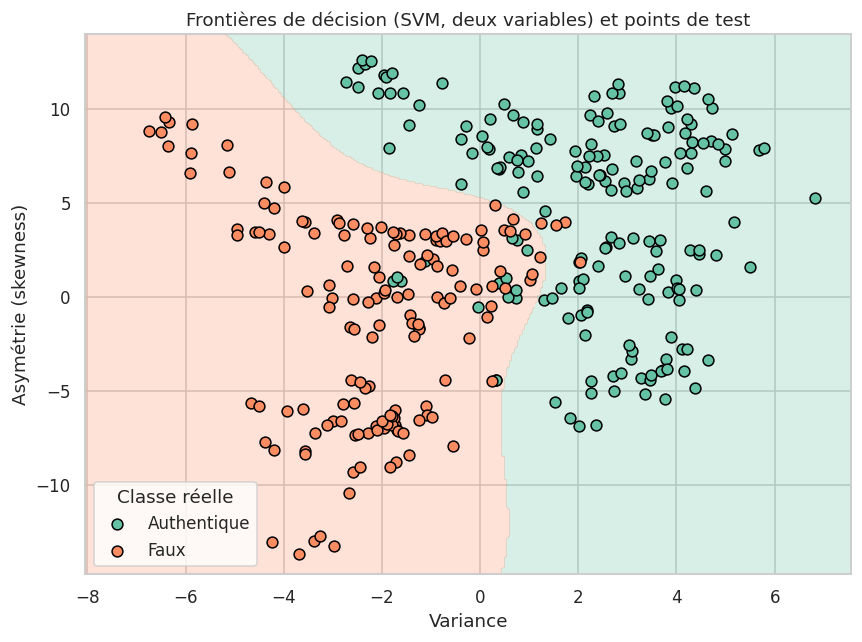

In [52]:
deux = ["variance", "skewness"]
modele_2d = Pipeline([("scaler", StandardScaler()),
                      ("svm", SVC(kernel="rbf"))])
modele_2d.fit(X_train[deux], y_train)

x_min, x_max = X_train[deux[0]].min() - 1, X_train[deux[0]].max() + 1
y_min, y_max = X_train[deux[1]].min() - 1, X_train[deux[1]].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grille = pd.DataFrame({deux[0]: xx.ravel(), deux[1]: yy.ravel()})
zz = modele_2d.predict(grille).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6))
couleurs = sns.color_palette("Set2")[:2]
ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], alpha=0.25, colors=couleurs)
for c, nom in [(0, "Authentique"), (1, "Faux")]:
    masque = y_test == c
    ax.scatter(X_test.loc[masque, deux[0]], X_test.loc[masque, deux[1]],
               label=nom, color=couleurs[c], s=50, edgecolor="k", zorder=3)
ax.set_xlabel("Variance")
ax.set_ylabel("Asymétrie (skewness)")
ax.set_title("Frontières de décision (SVM, deux variables) et points de test")
ax.legend(title="Classe réelle")
plt.tight_layout()
plt.show()

**Lecture.** Chaque zone colorée correspond à une classe prédite, avec les mêmes couleurs que les points de test. Avec seulement deux variables, la séparation est déjà bonne : les faux billets sont à gauche, les authentiques à droite. Les points situés près de la limite, vers une variance proche de 0 et une asymétrie entre 0 et 5, sont les plus difficiles à classer ; c'est là que deux variables seules se trompent le plus. Le modèle complet, qui utilise aussi l'aplatissement et l'entropie, lève la plupart de ces ambiguïtés. Cette figure illustre le principe de l'apprentissage supervisé : le modèle apprend une fonction qui partage l'espace des entrées en régions associées aux étiquettes.

## 9. Prédire un nouveau billet

Une fois le modèle validé, il sert à prédire l'authenticité d'un nouveau billet. Le pipeline applique automatiquement la même standardisation qu'à l'entraînement. Les deux billets ci-dessous sont **fictifs**, inventés pour l'exemple.

In [53]:
nouveaux = pd.DataFrame([
    {"variance": 3.5, "skewness": 8.0, "kurtosis": -3.0, "entropy": -0.5},
    {"variance": -2.5, "skewness": -6.0, "kurtosis": 7.0, "entropy": -1.0},
], index=["Billet A", "Billet B"])

resume = pd.DataFrame({
    "Prédiction": ["Faux" if p == 1 else "Authentique" for p in meilleur_pipe.predict(nouveaux)]
}, index=nouveaux.index)
if hasattr(meilleur_pipe, "predict_proba"):
    probas = meilleur_pipe.predict_proba(nouveaux)
    resume["P(authentique)"] = probas[:, 0].round(3)
    resume["P(faux)"] = probas[:, 1].round(3)
else:

    resume["Score de décision"] = meilleur_pipe.decision_function(nouveaux).round(3)
resume

,Prédiction,Score de décision
Billet A,Authentique,-1.375
Billet B,Faux,1.040


## 10. Synthèse, limites et questions

### Ce qu'il faut retenir

1. **Type d'apprentissage** : supervisé, classification binaire. La cible (authentique ou faux) est connue pour chaque billet.
2. **Démarche** : explorer, nettoyer (doublons), prétraiter dans un pipeline, comparer à une référence, valider par validation croisée stratifiée, évaluer une seule fois sur le test.
3. **Évaluation** : l'exactitude ne suffit pas. Le rappel de la classe « faux », la matrice de confusion et les courbes ROC et précision-rappel montrent où le modèle se trompe et à quel coût.
4. **Diagnostic** : la courbe d'apprentissage indique si le problème vient du manque de données ou de la complexité du modèle.

### Limites à connaître

- **Fuite de données** : les doublons, s'ils sont conservés, faussent l'évaluation. Toute transformation doit être apprise sur l'entraînement seul.
- **Déséquilibre** : les classes sont modérément déséquilibrées. D'où la stratification et le suivi du rappel et du PR-AUC, pas seulement de l'exactitude. Dans la réalité, les faux billets sont bien plus rares que dans ce jeu : la précision d'un détecteur y serait plus difficile à tenir.
- **Dérive temporelle** : les techniques de falsification évoluent. Un modèle entraîné sur des faux billets d'hier peut mal détecter ceux de demain.
- **Représentativité et biais** : le jeu contient 1 372 images obtenues avec un même protocole de numérisation. Un autre scanner, d'autres coupures ou d'autres types de faux pourraient donner des statistiques différentes.
- **Score très élevé** : quand plusieurs modèles frôlent la perfection, l'écart entre eux est dans le bruit de l'échantillonnage. Un jeu de test d'environ 340 billets ne permet pas de les départager de façon fiable.

> Ce TP est pédagogique : le modèle ne doit pas servir à une décision réelle de contrôle de billets.

### Questions

1. Pourquoi la référence « classe majoritaire » est-elle indispensable ? Quelle exactitude obtiendriez-vous en connaissant seulement l'effectif de chaque classe ?
2. Relancez la préparation **sans supprimer les doublons** (`df_propre = df.copy()`). Le score sur le test change-t-il ? Expliquez pourquoi c'est une fuite de données.
3. Modifiez `max_depth` de l'arbre de décision (1, 2, 4, 8, 16). Observez-vous du sous-apprentissage ou du surapprentissage ? Tracez l'exactitude en validation et en entraînement.
4. Supposons qu'un faux billet accepté coûte 10 fois plus qu'un vrai billet rejeté. Au lieu du seuil 0,5, cherchez un seuil sur `y_score` qui minimise le coût total sur la validation. Que devient le rappel ?
5. Ce problème pourrait-il être traité en apprentissage non supervisé ? Lancez un k-means à 2 groupes sur les variables standardisées et comparez-le à la classe réelle avec l'indice ARI.

> **Pour aller plus loin.** Retirez les variables une par une (par exemple `entropy`) et réentraînez la régression logistique : quelles statistiques sont indispensables à la détection ?